# Scene zero-shot baseline

Load two dog images, compare each with five descriptions using pretrained CLIP, and display the scores. No training is required. These are relative scene matches, not validated probabilities of why the dog barks.

Author: Elijah Ha

## 1. Setup

Assumes the project environment is installed and the scene datasets (`rf_leash` or `rf_bowl`) have already been prepared, just as the pose notebook assumes prepared pose data. Uses the shared data directory and validation split through `woofdata`.

CLIP additionally requires `transformers` and `torch` (the project `ml` extra). The first model run downloads pretrained weights. Scene annotations describe objects, not bark contexts, so this is a prediction demonstration rather than a five-category accuracy evaluation.

In [13]:
from pathlib import Path
import sys
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from transformers import CLIPModel, CLIPProcessor

# Locate the project from its root, notebooks folder, or CSSE416 workspace.
roots = [Path.cwd(), *Path.cwd().parents]
REPO_DIR = next((candidate for root in roots
                 for candidate in (root, root / "src/Project/dog-vocal-interpreter")
                 if (candidate / "src/woofdecoder/taxonomy.py").is_file()), None)
if REPO_DIR is None:
    raise RuntimeError("Start the kernel inside the project or CSSE416 workspace.")
sys.path.insert(0, str(REPO_DIR / "src"))

from woofdata.loader import load_sample
from woofdata.path import get_data_dir, load_data_dir_from_env_file
from woofdata.tasks import task_rows
from woofdecoder.taxonomy import CATEGORIES

load_data_dir_from_env_file(REPO_DIR / ".env")
DATA_DIR = get_data_dir()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Data:", DATA_DIR)
print("Device:", DEVICE)

Data: C:\Users\has\Desktop\CSSE416\src\Project\dog-vocal-interpreter\data
Device: cuda


## 2. Load two scene images

Select two reproducible samples from the prepared validation split. Keep test images for final reporting.

Validation images: 636
Sample 1: rf_leash/images/val/003019_jpg.rf.f371ddafac462fdfbf724cd83513caf3.jpg


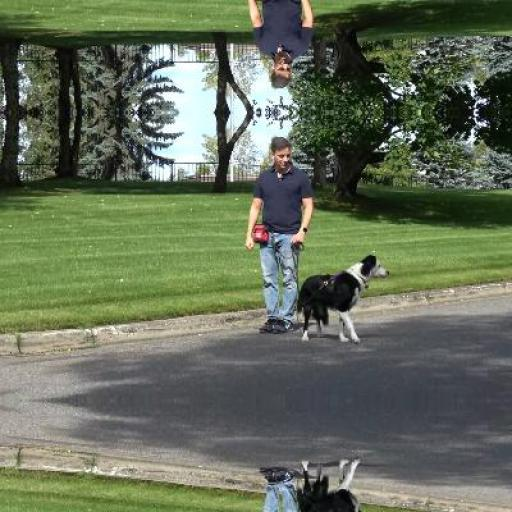

Sample 2: rf_leash/images/val/003439_jpg.rf.b5f13f9dea6df02952abfd8fd4482608.jpg


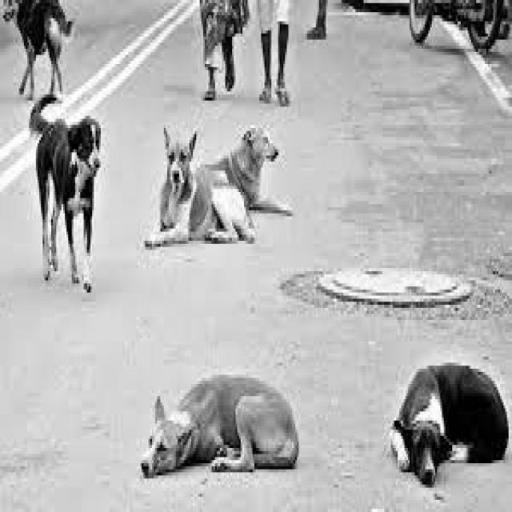

In [17]:
scene_rows = task_rows("scene_objects", "val", eval_only=True)
print("Validation images:", len(scene_rows))
if len(scene_rows) < 2:
    raise RuntimeError("This example needs at least two prepared scene validation images.")
selected_rows = scene_rows.sample(n=2)
samples = [load_sample("scene_objects", row) for _, row in selected_rows.iterrows()]
images = [Image.fromarray(sample.image) for sample in samples]
for number, (sample, image) in enumerate(zip(samples, images), start=1):
    print(f"Sample {number}: {sample.clip_id}")
    display(image)


## 3. Load CLIP and describe the categories

The first run downloads `openai/clip-vit-base-patch32` into the Hugging Face cache. These general descriptions avoid specifying particular objects or locations. They are exploratory prompts, not validated labels. `other` is a broad comparison description, not an uncertainty or rejection option.

In [20]:
MODEL_ID = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE).eval()

prompts = {
    "alert_aggressive": "A dog showing alert or aggressive behavior.",
    "playful_excited": "A dog showing playful or excited behavior.",
    "distressed_lonely": "A dog showing distress or loneliness.",
    "attention_seeking": "A dog seeking attention from a person.",
    "other": "A dog in another everyday situation.",
}
assert list(prompts) == list(CATEGORIES)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## 4. Display category scores

Scores sum to one across these five descriptions. They are uncalibrated and depend on prompt wording. Measuring category accuracy later requires independently labeled barking videos with dog-disjoint splits.

In [21]:
inputs = processor(text=[prompts[category] for category in CATEGORIES],
                   images=images, return_tensors="pt", padding=True)
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
with torch.inference_mode():
    scores = model(**inputs).logits_per_image.softmax(dim=-1).cpu().numpy()

for number, (sample, sample_scores) in enumerate(zip(samples, scores), start=1):
    print(f"Sample {number}: {sample.clip_id}")
    results = pd.DataFrame({"category": CATEGORIES, "relative_score": sample_scores})
    display(results.sort_values("relative_score", ascending=False).reset_index(drop=True))


Sample 1: rf_leash/images/val/003019_jpg.rf.f371ddafac462fdfbf724cd83513caf3.jpg


,category,relative_score
0,other,0.575592
1,attention_seeking,0.211006
2,alert_aggressive,0.117889
3,playful_excited,0.077119
4,distressed_lonely,0.018395


Sample 2: rf_leash/images/val/003439_jpg.rf.b5f13f9dea6df02952abfd8fd4482608.jpg


,category,relative_score
0,distressed_lonely,0.455633
1,other,0.446424
2,alert_aggressive,0.052499
3,attention_seeking,0.044256
4,playful_excited,0.001188
